In [1]:
from feat.detector import Detector

# The verbose flag will print out messages indicating whether a pre-trained model
# is being downloaded for the first time, or being loaded from disk.
# In this case I already have all the models downloaded, but if you run this notebook on
# your personal computer or Google Collab, these will be downloaded the first time you
# use a Detector.
detector = Detector(verbose=True)

detector

/opt/anaconda3/envs/videop/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:root:Verbose logging enabled
INFO:root:Loading Face model: retinaface
INFO:root:Loading Facial Landmark model: mobilefacenet
INFO:root:Loading facepose model: img2pose


Using downloaded and verified file: /opt/anaconda3/envs/videop/lib/python3.11/site-packages/feat/resources/mobilenet0.25_Final.pth
Using downloaded and verified file: /opt/anaconda3/envs/videop/lib/python3.11/site-packages/feat/resources/mobilefacenet_model_best.pth.tar
Using downloaded and verified file: /opt/anaconda3/envs/videop/lib/python3.11/site-packages/feat/resources/July4_AU1_XGB.ubj
Using downloaded and verified file: /opt/anaconda3/envs/videop/lib/python3.11/site-packages/feat/resources/all_data_Upperpca_June30.pkl
Using downloaded and verified file: /opt/anaconda3/envs/videop/lib/python3.11/site-packages/feat/resources/all_data_Upperscalar_June30.pkl
Using downloaded and verified file: /opt/anaconda3/envs/videop/lib/python3.11/site-packages/feat/resources/all_data_Lowerpca_June30.pkl
Using downloaded and verified file: /opt/anaconda3/envs/videop/lib/python3.11/site-packages/feat/resources/all_data_Lowerscalar_June30.pkl
Using downloaded and verified file: /opt/anaconda3/env

INFO:root:Loading AU model: xgb
INFO:root:Loading emotion model: resmasknet
INFO:root:Loading Identity model: facenet


feat.detector.Detector(face_model=retinaface, landmark_model=mobilefacenet, au_model=xgb, emotion_model=resmasknet, facepose_model=img2pose, identity_model=facenet)

In [2]:
from feat import Detector

detector = Detector(
    face_model="retinaface",
    landmark_model="mobilefacenet",
    au_model='xgb',
    emotion_model="resmasknet",
    facepose_model="img2pose",
)

detector

INFO:root:Loading Face model: retinaface
INFO:root:Loading Facial Landmark model: mobilefacenet
INFO:root:Loading facepose model: img2pose
INFO:root:Loading AU model: xgb
INFO:root:Loading emotion model: resmasknet
INFO:root:Loading Identity model: facenet


feat.detector.Detector(face_model=retinaface, landmark_model=mobilefacenet, au_model=xgb, emotion_model=resmasknet, facepose_model=img2pose, identity_model=facenet)

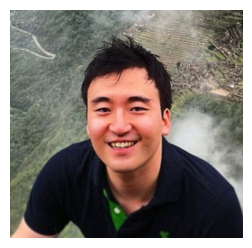

In [3]:
from feat.utils.io import get_test_data_path
from feat.plotting import imshow
import os

# Helper to point to the test data folder
test_data_dir = get_test_data_path()

# Get the full path
single_face_img_path = os.path.join(test_data_dir, "single_face.jpg")

# Plot it
imshow(single_face_img_path)

In [4]:
single_face_prediction = detector.detect_image(single_face_img_path)

# Show results
single_face_prediction.aus

  0%|          | 0/1 [00:00<?, ?it/s]INFO:root:detecting faces...
INFO:root:detecting landmarks...
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 310, 310]) to 112
INFO:root:detecting poses...
INFO:root:detecting aus...
INFO:root:detecting emotions...
INFO:root:detecting identity...
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 310, 310]) to 112
INFO:root:inverting face transform...
INFO:root:inverting landmark transform...
INFO:root:creating fex output...
100%|██████████| 1/1 [00:01<00:00,  1.11s/it]


,AU01,AU02,AU04,AU05,AU06,AU07,AU09,AU10,AU11,AU12,AU14,AU15,AU17,AU20,AU23,AU24,AU25,AU26,AU28,AU43
0,0.604805,0.293292,0.051011,0.285801,0.917875,1.0,0.356386,0.619562,1.0,0.953904,0.722208,0.072662,0.154148,1.0,0.174083,0.015777,0.999801,0.868804,0.027718,0.116028


In [5]:
single_face_prediction.emotions

,anger,disgust,fear,happiness,sadness,surprise,neutral
0,0.00051,0.000026,0.002214,0.991036,0.000028,0.006158,0.000029


In [6]:
single_face_prediction.faceboxes

,FaceRectX,FaceRectY,FaceRectWidth,FaceRectHeight,FaceScore
0,192.507747,140.455324,179.352715,259.257723,0.999708


In [8]:
single_face_prediction.emotions

,anger,disgust,fear,happiness,sadness,surprise,neutral
0,0.00051,0.000026,0.002214,0.991036,0.000028,0.006158,0.000029


In [9]:
single_face_prediction.poses # (in degrees)

,Pitch,Roll,Yaw
0,0.811819,-3.737926,6.101121


In [10]:
single_face_prediction.to_csv("output.csv", index=False)

## Loading detection results from a saved file

In [11]:
# prefer to pandas read_csv
from feat.utils.io import read_feat

input_prediction = read_feat("output.csv")

# Show results
input_prediction

,FaceRectX,FaceRectY,FaceRectWidth,FaceRectHeight,FaceScore,x_0,x_1,x_2,x_3,x_4,...,Identity_505,Identity_506,Identity_507,Identity_508,Identity_509,Identity_510,Identity_511,Identity_512,input,frame
0,192.507747,140.455324,179.352715,259.257723,0.999708,187.430431,188.301042,190.157303,194.596445,203.539794,...,-0.005776,-0.035352,-0.001157,0.001913,0.117051,-0.001347,-0.012121,0.029357,/opt/anaconda3/envs/videop/lib/python3.11/site...,0


# Visualizing detection results.

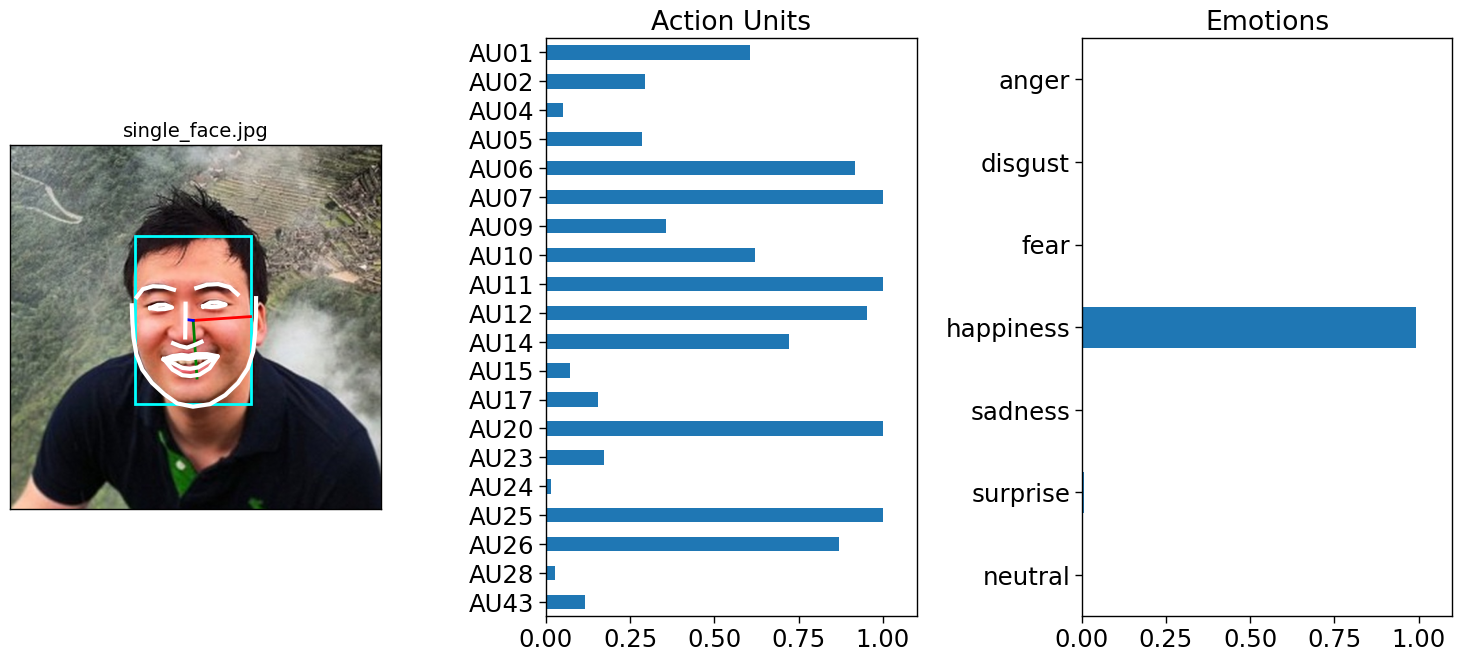

In [12]:
figs = single_face_prediction.plot_detections(poses=True)

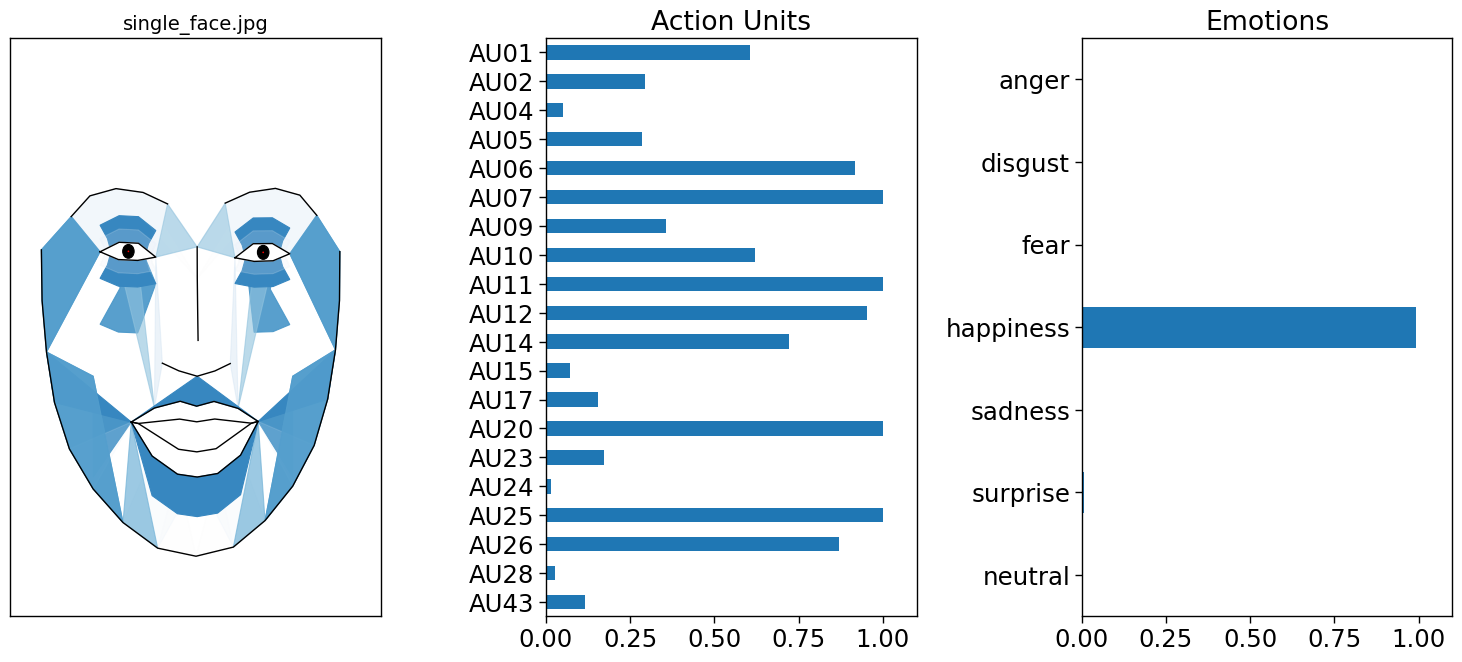

In [13]:
figs = single_face_prediction.plot_detections(faces='aus', muscles=True)

## Detecting multiple faces from a single image

In [14]:
multi_face_image_path = os.path.join(test_data_dir, "multi_face.jpg")
multi_face_prediction = detector.detect_image(multi_face_image_path)

# Show results
multi_face_prediction

  0%|          | 0/1 [00:00<?, ?it/s]INFO:root:detecting faces...
INFO:root:detecting landmarks...
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 160, 160]) to 112
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 148, 148]) to 112
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 144, 144]) to 112
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 120, 120]) to 112
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 132, 132]) to 112
INFO:root:detecting poses...
INFO:root:detecting aus...
INFO:root:detecting emotions...
INFO:root:detecting identity...
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescali

,FaceRectX,FaceRectY,FaceRectWidth,FaceRectHeight,FaceScore,x_0,x_1,x_2,x_3,x_4,...,Identity_505,Identity_506,Identity_507,Identity_508,Identity_509,Identity_510,Identity_511,Identity_512,input,frame
0,683.340962,288.568895,105.420755,134.124931,0.999817,685.511870,683.331586,682.070848,682.695525,686.402923,...,0.033936,-0.041451,-0.010431,-0.050652,0.057576,-0.016750,0.052456,0.071331,/opt/anaconda3/envs/videop/lib/python3.11/site...,0
1,531.699620,309.095124,97.330348,123.796507,0.999361,534.246679,532.407478,531.774721,532.450397,535.062077,...,0.074216,-0.008548,-0.043167,0.008296,0.081963,-0.031615,0.053231,0.031800,/opt/anaconda3/envs/videop/lib/python3.11/site...,0
2,316.664986,236.808286,91.607044,120.287694,0.998966,313.592758,314.633878,316.859562,320.841330,327.401504,...,0.037859,-0.039686,-0.053666,-0.062578,-0.022025,-0.039633,-0.027346,0.017940,/opt/anaconda3/envs/videop/lib/python3.11/site...,0
3,435.052554,211.107515,81.976803,101.041442,0.994319,436.121349,436.979648,438.452164,440.423172,443.637487,...,0.028489,-0.064772,-0.014781,-0.011815,0.037212,0.053282,0.051709,0.041597,/opt/anaconda3/envs/videop/lib/python3.11/site...,0
4,220.073854,64.653715,85.268401,110.928946,0.994262,219.496103,217.772572,216.813993,217.033579,219.753720,...,0.042779,0.054387,0.000781,0.039160,0.068925,-0.011794,0.028254,-0.062116,/opt/anaconda3/envs/videop/lib/python3.11/site...,0


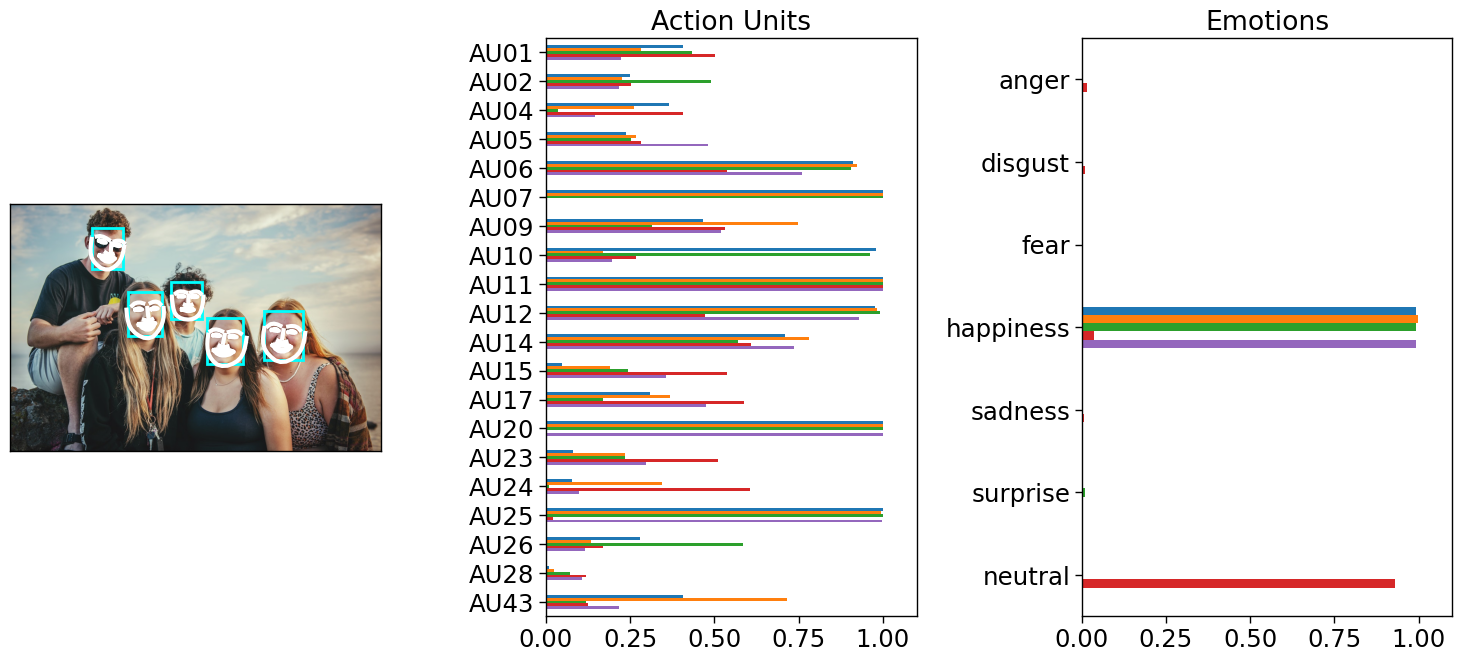

In [15]:
figs = multi_face_prediction.plot_detections(add_titles=False)

In [16]:
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
import seaborn as sns
from tqdm import tqdm
sns.set_context("talk")

In [17]:
import os
import urllib.request
import pandas as pd
import numpy as np
from glob import glob

# File IDs and names
files_to_download = {
    "4c5mb": 'clip_attrs.csv',
    "n6rt3": '001.mp4',
    "3gh8v": '002.mp4',
    "twqxs": '003.mp4',
    "nc7d9": '004.mp4',
    "nrwcm": '005.mp4',
    "2rk9c": '006.mp4',
    "mxkzq": '007.mp4',
    "c2na7": '008.mp4',
    "wj7zy": '009.mp4',
    "mxywn": '010.mp4',
    "6bn3g": '011.mp4',
    "jkwsp": '012.mp4',
    "54gtv": '013.mp4',
    "c3hpm": '014.mp4',
    "utdqj": '015.mp4',
    "hpw4a": '016.mp4',
    "94swe": '017.mp4',
    "qte5y": '018.mp4',
    "aykvu": '019.mp4',
    "3d5ry": '020.mp4',
}

# Function to download files using urllib
def download_file(url, fname):
    try:
        print(f"Downloading: {fname}")
        urllib.request.urlretrieve(url, fname)
    except Exception as e:
        print(f"Failed to download {fname}: {e}")

# Download each file
for fid, fname in files_to_download.items():
    if not os.path.exists(fname):
        url = f"https://osf.io/{fid}/download"
        download_file(url, fname)

# List of downloaded videos
videos = np.sort(glob("*.mp4"))

# Load in attributes
clip_attrs = pd.read_csv("clip_attrs.csv")

# Add in file names and rename conditions
clip_attrs = clip_attrs.assign(
    input=clip_attrs.clipN.apply(lambda x: str(x).zfill(3) + ".mp4"),
    condition=clip_attrs["class"].replace({"gn": "goodNews", "ists": "badNews"}),
)

# We're only using a subset of videos for this tutorial so drop the rest
clip_attrs = clip_attrs.query("input in @videos")

print(f"Downloaded {len(videos)} videos")
print(f"Downloaded attributes files with {clip_attrs.shape[0]} rows")


Downloaded 20 videos
Downloaded attributes files with 20 rows


## 5.2 Extract facial features using Detector

In [ ]:
vid = "/Users/jeremiah/video-p-reaction-joketype-modular/data/videos/ZRSRdA.joke2.rep2.take1.TearingPaper.mp4"

In [28]:
# Initialize the default detector
detector = Detector()
  # This is the line that does detection!
fex = detector.detect_video(video)

INFO:root:Loading Face model: retinaface
INFO:root:Loading Facial Landmark model: mobilefacenet
INFO:root:Loading facepose model: img2pose
INFO:root:Loading AU model: xgb
INFO:root:Loading emotion model: resmasknet
INFO:root:Loading Identity model: facenet
  0%|          | 0/66 [00:00<?, ?it/s]INFO:root:VideoDataset: RESCALING WARNING: from (1080, 1080) to output_size=700
INFO:root:detecting faces...
INFO:root:detecting landmarks...
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 400, 400]) to 112
INFO:root:detecting poses...
INFO:root:detecting aus...
INFO:root:detecting emotions...
INFO:root:detecting identity...
INFO:root:RESCALING WARNING: image_operations.extract_face_from_bbox() is rescaling cropped img with shape torch.Size([3, 400, 400]) to 112
INFO:root:inverting face transform...
INFO:root:inverting landmark transform...
INFO:root:creating fex output...
  2%|▏         | 1/66 [00:01<01:14,  1.15s/it]INFO

In [33]:
fex.to_csv("pakbooo.csv", index=False)

In [18]:
from feat import Detector

# Initialize the default detector
detector = Detector()

# Loop over and process each video and save results to csv
for video in tqdm(videos):
    out_name = video.replace(".mp4", ".csv")
    if not os.path.exists(out_name):

        print(f"Processing: {video}")

        # This is the line that does detection!
        fex = detector.detect_video(video)

        fex.to_csv(out_name, index=False)

INFO:root:Loading Face model: retinaface
INFO:root:Loading Facial Landmark model: mobilefacenet
INFO:root:Loading facepose model: img2pose
INFO:root:Loading AU model: xgb
INFO:root:Loading emotion model: resmasknet
INFO:root:Loading Identity model: facenet
100%|██████████| 20/20 [00:00<00:00, 6369.48it/s]


## Aggregate detections using a Fex dataframe

In [19]:
from feat.utils.io import read_feat

fex = pd.concat(map(lambda video: read_feat(video.replace(".mp4", ".csv")), videos))

print(f"Unique videos: {fex.inputs.nunique()}")
print(f"Total processed frames: {fex.shape[0]}")
print(f"Avg frames per video: {fex.groupby('input').size().mean()}")

Unique videos: 20
Total processed frames: 947
Avg frames per video: 47.35


In [20]:
fex.shape
fex.head()

,FaceRectX,FaceRectY,FaceRectWidth,FaceRectHeight,FaceScore,x_0,x_1,x_2,x_3,x_4,...,Identity_506,Identity_507,Identity_508,Identity_509,Identity_510,Identity_511,Identity_512,input,frame,approx_time
0,364.948101,281.563424,393.658531,537.702853,0.999346,358.029120,364.115807,373.340541,385.406547,407.695811,...,-0.016379,-0.032188,0.014257,-0.018239,-0.031981,0.026821,-0.003266,001.mp4,0,00:00
1,364.974209,281.557915,393.618768,537.833041,0.999347,358.282129,364.299575,373.460059,385.468946,407.703749,...,-0.016489,-0.032055,0.014253,-0.018346,-0.031937,0.026831,-0.003196,001.mp4,1,00:00
2,367.373317,279.992693,392.348647,539.271136,0.999402,360.173095,366.347707,375.705273,387.914289,410.324029,...,-0.016297,-0.030854,0.016356,-0.016339,-0.030639,0.027668,-0.002699,001.mp4,2,00:00
3,369.249343,278.803627,393.084903,542.412503,0.999301,361.106219,366.753447,375.681848,387.628947,409.960173,...,-0.017205,-0.029063,0.017791,-0.016693,-0.029910,0.029721,-0.002438,001.mp4,3,00:00
4,368.264246,273.054309,397.936984,549.070642,0.999246,359.114144,365.708650,375.771074,388.742694,411.348607,...,-0.009046,-0.022098,0.013248,-0.012189,-0.032007,0.023544,-0.000947,001.mp4,4,00:00


## Summarize data with Fex.sessions

In [21]:
by_video = fex.update_sessions(fex["input"])

# Compute the mean per video
video_means = by_video.extract_mean()

video_means # 20 rows for 20 videos

,mean_FaceRectX,mean_FaceRectY,mean_FaceRectWidth,mean_FaceRectHeight,mean_FaceScore,mean_x_0,mean_x_1,mean_x_2,mean_x_3,mean_x_4,...,mean_Identity_504,mean_Identity_505,mean_Identity_506,mean_Identity_507,mean_Identity_508,mean_Identity_509,mean_Identity_510,mean_Identity_511,mean_Identity_512,mean_frame
001.mp4,362.084484,275.420925,392.002061,540.084850,0.999371,354.405600,361.038742,371.394996,384.487880,406.916349,...,0.031831,0.052317,-0.011516,-0.020479,0.006933,-0.025736,-0.026527,0.012694,-0.005461,19.5
002.mp4,362.337597,270.662703,384.199809,539.799554,0.999327,353.534095,358.986993,368.182524,380.593914,402.246689,...,0.032564,0.054282,-0.006172,-0.012435,0.008941,-0.008779,-0.034628,0.031621,0.005050,13.5
003.mp4,356.414586,270.113668,388.752962,543.399316,0.999360,344.468241,348.771534,356.321914,367.162643,388.019181,...,0.033476,0.057526,-0.011520,-0.013398,0.001560,-0.011585,-0.039984,0.035728,0.005776,23.0
004.mp4,341.109903,272.020490,390.492014,546.438416,0.999389,330.759937,336.258346,344.861156,356.738530,378.529182,...,0.025768,0.059985,-0.015268,-0.019848,0.014849,-0.008858,-0.038305,0.043853,0.005582,22.0
005.mp4,322.778669,291.587059,394.996838,541.148296,0.999355,314.334572,319.992770,329.254694,341.965566,364.796634,...,0.022941,0.056270,-0.011774,-0.029233,0.013753,-0.014302,-0.033361,0.018869,-0.005395,22.0
006.mp4,352.045237,262.661999,385.354274,543.198747,0.999402,341.920622,345.582289,352.609616,362.821066,382.898333,...,0.027722,0.052212,-0.007074,-0.014814,0.008103,0.002672,-0.031357,0.021920,0.008952,23.5
007.mp4,359.267957,266.689710,386.354507,540.448862,0.999362,347.946001,350.752681,356.958874,366.397815,385.752921,...,0.025614,0.061173,-0.008604,-0.008727,0.004778,0.013164,-0.030991,0.031033,0.009334,13.0
008.mp4,335.279899,269.097499,390.375570,544.967241,0.999301,324.578346,330.237464,339.032122,350.334470,370.712164,...,0.027744,0.057112,-0.011814,-0.013111,0.014505,-0.013056,-0.027330,0.037262,0.003208,17.5
009.mp4,341.579122,258.624592,385.419378,548.219189,0.999311,330.085497,335.875672,344.869530,356.883599,378.331751,...,0.028308,0.059198,-0.015076,-0.009961,0.007898,-0.007468,-0.030621,0.038470,0.005611,20.5
010.mp4,350.280871,283.854535,384.202183,539.528793,0.999410,339.368385,345.362964,355.072036,367.588712,389.892907,...,0.030773,0.052591,-0.011871,-0.010483,0.003934,-0.022676,-0.023258,0.018831,0.008544,26.5


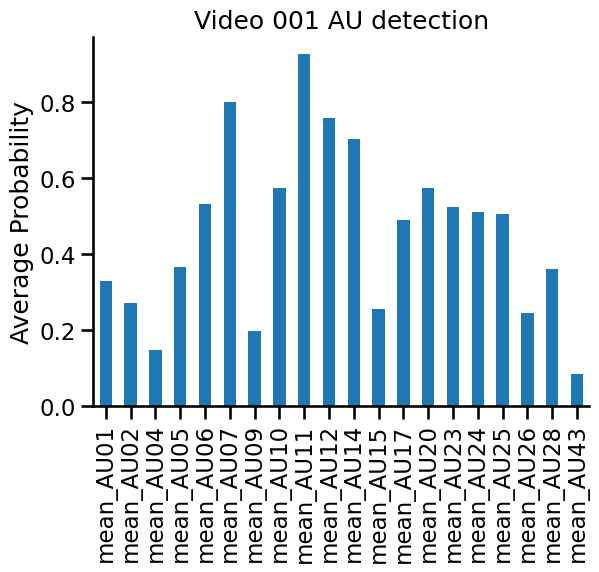

In [22]:
# Grab the aus just for video 1
video001_aus = video_means.aus.loc['001.mp4']
# video001_aus = video_means.aus.loc['001.csv'] # if loading pre-computed csv

# Plot them
ax = video001_aus.plot(kind='bar', title='Video 001 AU detection');
ax.set(ylabel='Average Probability');
sns.despine();

## Chaining operations

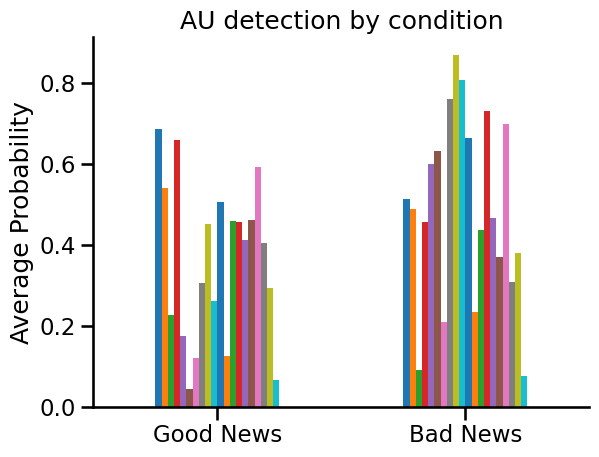

In [23]:
# Which condition each video belonged to
video2condition = dict(
    zip(
        # if loading pre-computed csv
        # clip_attrs["input"].str.replace(".mp4", ".csv", regex=False),
        clip_attrs["input"],
        clip_attrs["condition"],
    )
)

# Update sesssions to group by condition, compute means (per condition), and make a
# barplot of the mean AUs for each condition
ax = (
    by_video.update_sessions(video2condition)
    .extract_mean()
    .aus.plot(kind="bar", legend=False, title="Mean AU detection by condition")
)
ax.set(ylabel='Average Probability', title='AU detection by condition', xticklabels=['Good News', 'Bad News']);
plt.xticks(rotation=0);
sns.despine();

In [24]:
aus = ["AU06", "AU12", "AU25"]  # from https://py-feat.org/pages/au_reference.html

# Update the sessions to condition compute summary stats
summary = by_video.update_sessions(video2condition).extract_summary(
    mean=True, sem=True, std=False, min=False, max=False
)

# Organize them for plotting
bad_means = summary.loc["badNews", [f"mean_{au}" for au in aus]]
bad_sems = summary.loc["badNews", [f"sem_{au}" for au in aus]]
good_means = summary.loc["goodNews", [f"mean_{au}" for au in aus]]
good_sems = summary.loc["goodNews", [f"sem_{au}" for au in aus]]



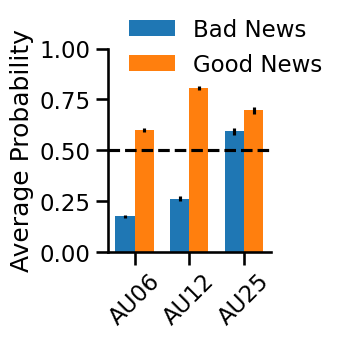

In [25]:
# Plot
fig, ax = plt.subplots(figsize=(3, 4))
ind = np.arange(len(bad_means))
width = 0.35
rects1 = ax.bar(ind - width / 2, bad_means, width, yerr=bad_sems, label="Bad News");
rects2 = ax.bar(ind + width / 2, good_means, width, yerr=good_sems, label="Good News");
ax.set(ylabel="Average Probability", title="", xticks=ind, xticklabels=aus, ylim=(0, 1));
ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0, 1.25));
plt.axhline(0.5, ls="--", color="k");
sns.despine();
plt.xticks(rotation=45);
plt.tight_layout();
plt.savefig('./au_diffs.pdf', bbox_inches='tight');

## Comparing the condition difference across AUs using regression

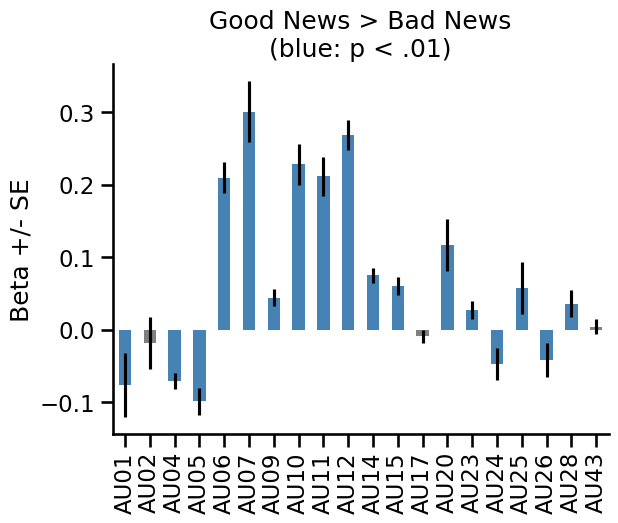

In [26]:
# Save the by_condition fex from above
by_condition = video_means.update_sessions(video2condition)

# We set numerical contrasts to compare mean good news > mean bad news
by_condition_codes = by_condition.update_sessions({"goodNews": 1., "badNews": -1})

# Now we perform a regression (t-test) at every AU
b, se, t, p, df, residuals = by_condition_codes.regress(
    X="sessions", y="aus", fit_intercept=True
)

# We can perform bonferroni correction for multiple comparisions:
p_bonf = p / p.shape[1]

results = pd.concat(
    [
        b.round(3).loc[["sessions"]].rename(index={"sessions": "betas"}),
        se.round(3).loc[["sessions"]].rename(index={"sessions": "ses"}),
        t.round(3).loc[["sessions"]].rename(index={"sessions": "t-stats"}),
        df.round(3).loc[["sessions"]].rename(index={"sessions": "dof"}),
        p_bonf.round(3).loc[["sessions"]].rename(index={"sessions": "p-values"}),
    ]
)

ax = results.loc["betas"].plot(
    kind="bar",
    yerr=results.loc["ses"],
    color=[
        "steelblue" if elem else "gray"
        for elem in results.loc["p-values"] < 0.01
    ],
    title="Good News > Bad News\n(blue: p < .01)",
);
xticks = ax.get_xticklabels();
xticks = [elem.get_text().split('_')[-1] for elem in xticks]
ax.set_xticklabels(xticks);
ax.set_ylabel('Beta +/- SE');
sns.despine();

## Decoding condition from facial features

emotions model accuracy: 100% +/- 0%
aus model accuracy: 95% +/- 15%
poses model accuracy: 80% +/- 33.2%
emotions,poses model accuracy: 100% +/- 0%
aus,poses model accuracy: 85% +/- 22.9%


AttributeError: 'NoneType' object has no attribute 'remove'

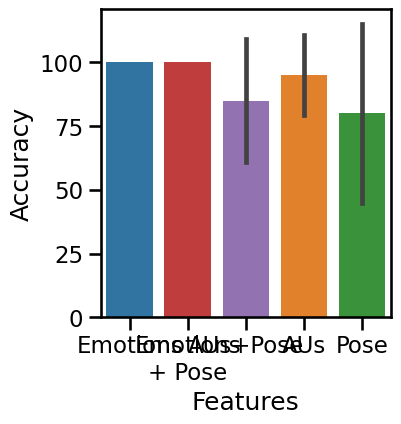

In [27]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import (
    StandardScaler,
)  # always a good idea to normalize your features!
from sklearn.pipeline import make_pipeline

# List of different models we'll train
feature_list = ["emotions", "aus", "poses", "emotions,poses", "aus,poses"]
results = []
models = {}

for features in feature_list:

    # .predict is just like .regress, but this time session is our y.
    model, accuracy = by_condition.predict(
        X=features,
        y="sessions",
        model=make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
        cv_kwargs={"cv": 10},
    )

    # Save the model
    models[features] = model

    # Save the performance for plotting
    results.append(
        pd.DataFrame(
            {"Accuracy": accuracy * 100, "Features": [features] * len(accuracy)}
        )
    )
    # Print performance
    print(
        f"{features} model accuracy: {accuracy.mean()*100:.3g}% +/- {accuracy.std()*100:.3g}%"
    )

# Concat results into a single dataframe and tweak column names
results = pd.concat(results).assign(
    Features=lambda df: df.Features.map(
        {
            "emotions": "Emotions",
            "poses": "Pose",
            "aus": "AUs",
            "emotions,poses": "Emotions\n+ Pose",
            "aus,poses": "AUs+Pose",
        }
    )
)
# Plot it
# with sns.plotting_context("talk", font_scale=1.8):
f, ax = plt.subplots(1, 1, figsize=(3.75,4));
ax = sns.barplot(
    x="Features",
    y="Accuracy",
    errorbar="sd",
    dodge=False,
    hue="Features",
    data=results,
    ax=ax,
    order=["Emotions", "Emotions\n+ Pose", "AUs+Pose", "AUs", "Pose"],
);
ax.get_legend().remove();
ax.set_title("Good News vs Bad News\nClassifier Performance");
ax.set(ylabel="Accuracy", xlabel="");
sns.despine();
plt.axhline(y=50, ls="--", color="k");
plt.xticks(rotation=90);
plt.tight_layout();

plt.savefig('./fig_maker/decoding_acc.pdf', bbox_inches='tight');

## Visualizing decoder weights

In [ ]:
from feat.plotting import plot_face

plot_face(
    au=models['aus'][1].coef_.squeeze(), # the LDA coefs from the AUs pipeline model
    feature_range=(0, 1),
    muscles={"all": "heatmap"},
    title="Expression reconstructed from\nAU classifier weights",
    title_kwargs={'wrap':False}
);
sns.despine(left=True,bottom=True);

plt.savefig('weights.pdf', bbox_inches='tight');

In [ ]:
from feat.plotting import animate_face

animation = animate_face(
    end=models['aus'][1].coef_.squeeze(), # same as before
    feature_range=(0, 1),
    muscles={'all': 'heatmap'},
    title="Good vs Bad News Classifier Weights",
    save="weights.gif",
)

# Time-series analysis

In [ ]:
# ISC returns a video x video pearson correlation matrix
isc = fex.isc(col = "happiness", method='pearson')

In [ ]:
def cluster_corrs(df):
    """Helper to reorder rows and cols of correlation matrix based on clustering"""

    import scipy.cluster.hierarchy as sch

    pairwise_distances = sch.distance.pdist(df)
    linkage = sch.linkage(pairwise_distances, method="complete")
    cluster_distance_threshold = pairwise_distances.max() / 2
    idx_to_cluster_array = sch.fcluster(
        linkage, cluster_distance_threshold, criterion="distance"
    )
    idx = np.argsort(idx_to_cluster_array)
    return df.iloc[idx, :].T.iloc[idx, :]

def add_cond_to_ticks(ax):
    """Helper to add condition info to each tick label"""
    xlabels, ylabels = [], []
    for xlabel, ylabel in zip(ax.get_xticklabels(), ax.get_yticklabels()):
        x_condition = video2condition[xlabel.get_text()]
        y_condition = video2condition[ylabel.get_text()]
        x_new = f"{x_condition[:-4]}_{xlabel.get_text().split('.csv')[0][1:]}"
        y_new = f"{y_condition[:-4]}_{ylabel.get_text().split('.csv')[0][1:]}"
        xlabels.append(x_new)
        ylabels.append(y_new)

    ax.set_xticklabels(xlabels);
    ax.set_yticklabels(ylabels);
    return ax

# Plot it
ax = sns.heatmap(
    cluster_corrs(isc),
    cmap="RdBu_r",
    vmin=-1, vmax=1,
    square=True,
)

ax = add_cond_to_ticks(ax)

ax.set(xlabel="", ylabel="", title="Inter-video Happiness\ntimeseries correlation");
plt.savefig('isc.pdf', bbox_inches='tight');